In [1]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_8/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Prophet. Часть 4: валидация, сравнение, ограничения

В частях 1–3 качество мы оценивали на глаз или по одному тестовому окну. Одна отсечка — это один случайный исход: другое окно могло дать другой вывод. Здесь:

1. **Кросс-валидация на временном ряде** — `cross_validation` и `performance_metrics`: ошибка как функция горизонта и покрытие интервалов.
2. **Тюнинг** гиперпараметров по CV.
3. **Сравнение с бейзлайнами** из `statsforecast` на тех же отсечках: дневной ряд Пейтона и почасовой трафик (из блока про TBATS).
4. **Когда Prophet не брать** — что видно по результатам CV.
5. Практика: дообучение с тёплым стартом и сохранение модели.



In [2]:
import itertools
import logging
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric
from prophet.serialize import model_from_json, model_to_json
from prophet.utilities import warm_start_params
from statsforecast import StatsForecast
from statsforecast.models import MSTL, AutoETS, AutoTBATS, Naive, SeasonalNaive
from statsmodels.graphics.tsaplots import plot_acf

logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").setLevel(logging.WARNING)
plt.rcParams["figure.figsize"] = (12, 4)

## 1. Кросс-валидация

### 1.1. Идея: исторические прогнозы

Выбираем в истории несколько **отсечек** (`cutoff`). Для каждой обучаем модель только на данных до отсечки и прогнозируем на `horizon` вперёд — получаем прогнозы, которые модель могла бы сделать в прошлом, и сравниваем их с фактом. Это скользящее окно с расширяющейся историей (expanding window).

Параметры `cross_validation`:
- `horizon` — горизонт прогноза;
- `initial` — минимальная длина обучения для первой отсечки (по умолчанию `3 * horizon`);
- `period` — шаг между отсечками (по умолчанию `horizon / 2`);
- или явный список дат `cutoffs`.

Отсечки считаются **с конца** ряда: последняя — за `horizon` до конца истории, дальше с шагом `period` назад, пока хватает `initial`. Модель передаётся необученной копией с теми же настройками: `cross_validation` сама переобучает её на каждой отсечке.



In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_8/data/example_wp_log_peyton_manning.csv", parse_dates=["ds"])
m = Prophet().fit(df)

start = time.perf_counter()
df_cv = cross_validation(m, initial="730 days", period="180 days", horizon="365 days", parallel="threads")
print(f"отсечек: {df_cv['cutoff'].nunique()}, прогнозов: {len(df_cv)}, {time.perf_counter() - start:.1f} с")
df_cv.head()

отсечек: 11, прогнозов: 3988, 1.0 с


,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2010-02-16,8.955438,8.456199,9.432008,8.242493,2010-02-15
1,2010-02-17,8.721831,8.252269,9.254972,8.008033,2010-02-15
2,2010-02-18,8.605553,8.099898,9.112817,8.045268,2010-02-15
3,2010-02-19,8.527360,8.022656,9.020083,7.928766,2010-02-15
4,2010-02-20,8.269266,7.789461,8.754947,7.745003,2010-02-15


Каждая строка — прогноз на дату `ds`, сделанный в момент `cutoff`. Отсечки независимы, поэтому их удобно обучать параллельно: `parallel="processes"` (рекомендация документации), `"threads"` или `"dask"` для кластера. Потоков достаточно: сама оптимизация идёт во внешнем процессе CmdStan, Python лишь ждёт его.

Один «исторический прогноз»:

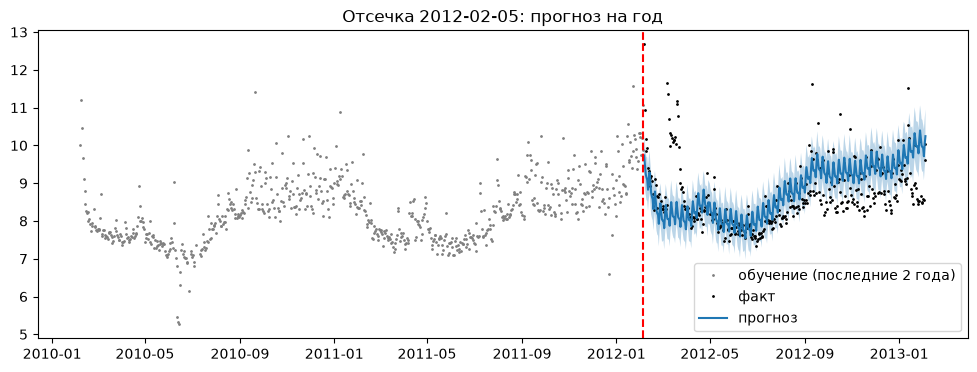

In [4]:
cutoff = df_cv["cutoff"].unique()[4]
one = df_cv[df_cv["cutoff"] == cutoff]
history = df[(df["ds"] <= cutoff) & (df["ds"] > cutoff - pd.Timedelta(days=730))]

fig, ax = plt.subplots()
ax.plot(history["ds"], history["y"], ".", ms=2, color="grey", label="обучение (последние 2 года)")
ax.plot(one["ds"], one["y"], ".", ms=2, color="black", label="факт")
ax.plot(one["ds"], one["yhat"], label="прогноз")
ax.fill_between(one["ds"], one["yhat_lower"], one["yhat_upper"], alpha=0.3)
ax.axvline(cutoff, ls="--", color="red")
ax.set_title(f"Отсечка {pd.Timestamp(cutoff):%Y-%m-%d}: прогноз на год")
ax.legend();

### 1.2. Метрики как функция горизонта

`performance_metrics` считает MSE, RMSE, MAE, MAPE, MdAPE, sMAPE и `coverage` (доля фактов внутри интервала). Прогнозы сортируются по горизонту `ds - cutoff`, метрика усредняется скользящим окном из `rolling_window` = 10 % прогнозов. Поэтому первая строка — горизонт 37 дней: в окне прогнозы на 1…37 дней.

In [5]:
df_p = performance_metrics(df_cv)
df_p.iloc[::60]

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,37 days,0.493403,0.702427,0.505453,0.058592,0.050291,0.058865,0.682960
60,97 days,0.430253,0.655937,0.519037,0.062494,0.053928,0.062156,0.613522
120,157 days,0.493908,0.702786,0.531981,0.065764,0.051889,0.064698,0.645729
180,217 days,0.758590,0.870971,0.658455,0.077585,0.062980,0.077150,0.553221
240,277 days,0.590569,0.768485,0.633298,0.077545,0.067505,0.076586,0.577661
300,337 days,0.774788,0.880221,0.713859,0.089122,0.075444,0.088991,0.545683


`rolling_window=1` — одно число на весь горизонт (так удобно сравнивать модели и тюнить):

In [6]:
performance_metrics(df_cv, rolling_window=1)

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,365 days,0.668151,0.817405,0.628742,0.075641,0.06197,0.075144,0.585005


`plot_cross_validation_metric` — то же графиком: точки — ошибка каждого прогноза, линия — скользящее среднее.

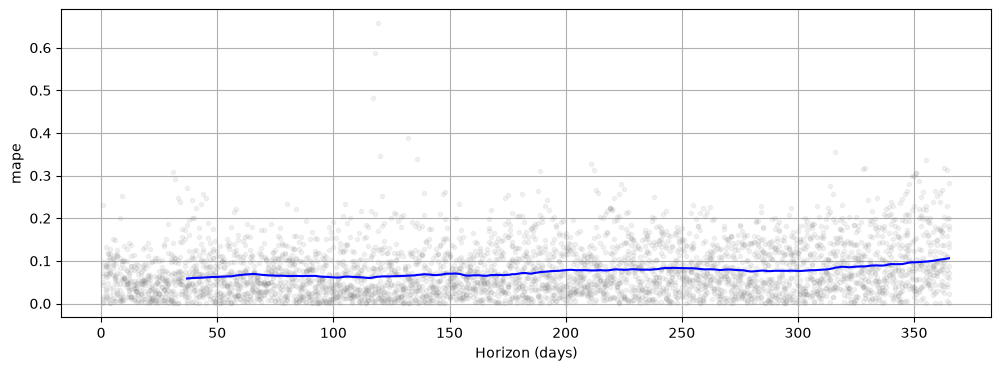

In [7]:
fig = plot_cross_validation_metric(df_cv, metric="mape", figsize=(12, 4))

Ошибка растёт с горизонтом: около 6 % на ближнем горизонте, около 10 % на годовом. Это главный ответ CV — **на какой горизонт модели можно доверять**.

### 1.3. Покрытие интервалов

У 80 %-интервала покрытие должно быть около 0.8 на любом горизонте.

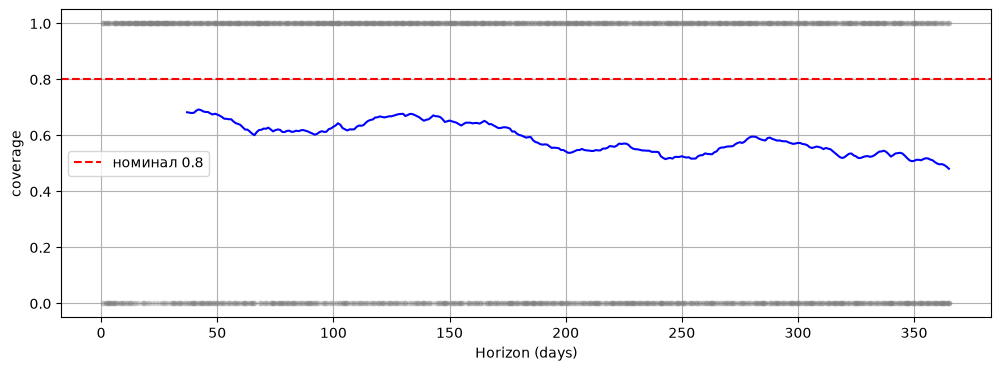

In [8]:
fig = plot_cross_validation_metric(df_cv, metric="coverage", figsize=(12, 4))
plt.axhline(0.8, color="red", ls="--", label="номинал 0.8")
plt.legend();

Покрытие ниже номинала и падает с горизонтом: интервалы **слишком узкие**. Это ожидаемо из части 1, раздел 4: интервал учитывает только шум $\sigma$ и симуляцию будущих изломов тренда. Не учтены:
- неопределённость параметров — сезонности, праздников (её даёт только `mcmc_samples > 0`);
- автокорреляция остатков — модель считает шум независимым (раздел 4.1);
- изменения, которых не было в истории.

Документация сама предупреждает, что интервалы Prophet — ориентир, а не гарантия. Проверять их нужно по coverage на CV, как здесь.

## 2. Тюнинг гиперпараметров

Сетка из документации: `changepoint_prior_scale` × `seasonality_prior_scale` по 4 значения в логарифмической шкале (обе ручки — масштабы приоров, то есть силы штрафа). Метрика — RMSE на горизонте 30 дней по трём отсечкам.

In [9]:
param_grid = {
    "changepoint_prior_scale": [0.001, 0.01, 0.1, 0.5],
    "seasonality_prior_scale": [0.01, 0.1, 1.0, 10.0],
}
tuning_cutoffs = pd.to_datetime(["2013-02-15", "2013-08-15", "2014-02-15"])

results = []
for values in itertools.product(*param_grid.values()):
    params = dict(zip(param_grid, values))
    cv = cross_validation(Prophet(**params).fit(df), cutoffs=tuning_cutoffs, horizon="30 days",
                          parallel="threads", disable_tqdm=True)
    results.append({**params, "rmse": performance_metrics(cv, rolling_window=1)["rmse"].iloc[0]})

tuning = pd.DataFrame(results)
tuning.pivot(index="changepoint_prior_scale", columns="seasonality_prior_scale", values="rmse").round(3)

seasonality_prior_scale,0.01,0.10,1.00,10.00
changepoint_prior_scale,,,,
0.001,0.757,0.750,0.753,0.759
0.010,0.528,0.540,0.543,0.542
0.100,0.523,0.519,0.517,0.524
0.500,0.529,0.530,0.527,0.529


In [10]:
tuning.loc[tuning["rmse"].idxmin()]

changepoint_prior_scale    0.1000
seasonality_prior_scale    1.0000
rmse                       0.5174
Name: 10, dtype: float64

- `changepoint_prior_scale` — самая влиятельная ручка: при 0.001 тренд недообучен, и RMSE почти в 1.5 раза хуже. Между 0.01 и 0.5 разница уже мала.
- `seasonality_prior_scale` почти ни на что не влияет — как и предсказывает документация (сезонность редко переобучается, раздел 3.4 части 2).

Оговорки:
- ошибку лучшей комбинации на тех же отсечках нельзя считать честной оценкой — мы выбрали минимум из 16 чисел. Для честной оценки нужны отдельные, более поздние отсечки;
- `changepoint_range` по CV не тюнят: по прошлым отсечкам не видно, как модель справится с изломом у самого края ряда;
- `holidays_prior_scale` и `seasonality_mode` можно добавить в ту же сетку; `n_changepoints`, `interval_width`, `uncertainty_samples` тюнить не нужно.

## 3. Сравнение с бейзлайнами

Ошибка Prophet сама по себе ни о чём не говорит: «MAPE 7 %» — это хорошо или плохо? Сравниваем с бейзлайнами из `statsforecast` **на тех же отсечках и том же горизонте**. Схема:
1. `StatsForecast.cross_validation` выбирает отсечки (`n_windows` окон с шагом `step_size` от конца ряда);
2. те же даты передаём в `cutoffs` Prophet;
3. сливаем прогнозы по `(ds, cutoff)`.

### 3.1. Дневной ряд: Пейтон

Модели statsforecast требуют регулярной сетки, а у Пейтона пропущено 59 дней. Заполним их интерполяцией — Prophet это не нужно, он учится на исходном ряде. Ошибку считаем только по наблюдённым датам.

Бейзлайны:
- `SeasonalNaive(7)` — значение неделю назад;
- `AutoETS(season_length=7)` — экспоненциальное сглаживание с недельной сезонностью;
- `MSTL([7, 365])` — разложение на недельную и годовую сезонности, тренд прогнозирует AutoETS.

AutoTBATS с периодом 365 на этом ряде обучается ~30 с на отсечку, поэтому его оставим для трафика.

In [11]:
H_DAYS = 365
peyton = df.set_index("ds").asfreq("D").interpolate().reset_index().assign(unique_id="peyton")
print("заполнено пропусков:", len(peyton) - len(df))

daily_models = [SeasonalNaive(season_length=7), AutoETS(season_length=7),
                MSTL(season_length=[7, 365], trend_forecaster=AutoETS(model="ZZN"))]
cv_daily = StatsForecast(models=daily_models, freq="D").cross_validation(
    df=peyton, h=H_DAYS, n_windows=6, step_size=180
)
daily_cutoffs = pd.to_datetime(cv_daily["cutoff"].unique())
daily_cutoffs

заполнено пропусков: 59


<DatetimeArray>
['2012-08-03 00:00:00', '2013-01-30 00:00:00', '2013-07-29 00:00:00',
 '2014-01-25 00:00:00', '2014-07-24 00:00:00', '2015-01-20 00:00:00']
Length: 6, dtype: datetime64[ns]

In [12]:
def compare(df_prophet_cv: dict[str, pd.DataFrame], df_sf_cv: pd.DataFrame) -> pd.DataFrame:
    """Склеивает CV Prophet-моделей с CV statsforecast по (ds, cutoff): одна строка — один прогноз."""
    out = df_sf_cv.drop(columns=["unique_id", "y"])
    for name, cv in df_prophet_cv.items():
        out = out.merge(cv[["ds", "cutoff", "y", "yhat"]].rename(columns={"yhat": name}), on=["ds", "cutoff"],
                        suffixes=("_drop", ""))
    return out.drop(columns=out.columns[out.columns.str.endswith("_drop")])


cv_prophet = cross_validation(Prophet().fit(df), cutoffs=daily_cutoffs, horizon=f"{H_DAYS} days", parallel="threads")
daily = compare({"Prophet": cv_prophet}, cv_daily)
daily_names = ["Prophet"] + [str(model) for model in daily_models]
daily[daily_names].sub(daily["y"], axis=0).abs().mean().rename("MAE").round(3)

Prophet          0.564
SeasonalNaive    1.137
AutoETS          1.024
MSTL             0.545
Name: MAE, dtype: float64

Ошибку по горизонтам посчитаем тем же `performance_metrics`: ему нужны только столбцы `ds`, `cutoff`, `y`, `yhat`.

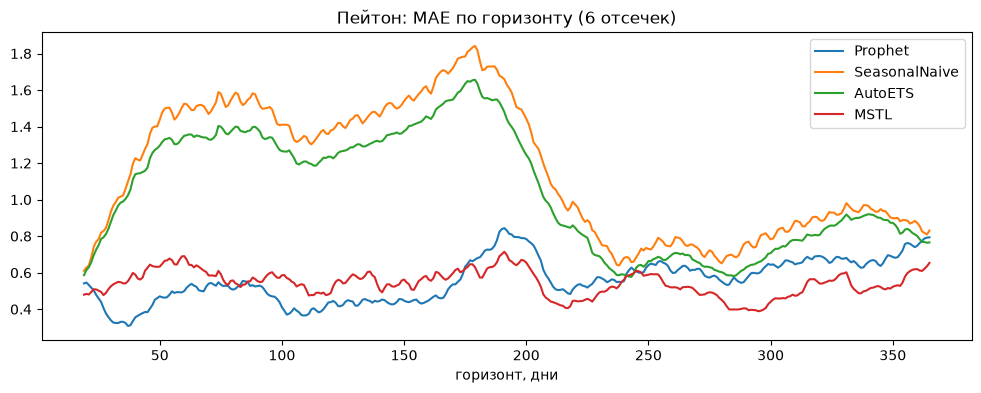

In [13]:
def mae_by_horizon(cv: pd.DataFrame, names: list[str], rolling_window: float = 0.05) -> pd.DataFrame:
    return pd.concat({
        name: performance_metrics(cv.assign(yhat=cv[name]), metrics=["mae"], rolling_window=rolling_window)
        .set_index("horizon")["mae"]
        for name in names
    }, axis=1)


ax = mae_by_horizon(daily, daily_names).pipe(lambda t: t.set_axis(t.index.days)).plot(
    title="Пейтон: MAE по горизонту (6 отсечек)"
)
ax.set_xlabel("горизонт, дни");

Скользящее окно сглаживает самые короткие горизонты, поэтому их удобнее смотреть таблицей по корзинам:

In [14]:
horizon_days = (daily["ds"] - daily["cutoff"]).dt.days
buckets = pd.cut(horizon_days, [0, 7, 30, 90, 180, 365], labels=["1–7", "8–30", "31–90", "91–180", "181–365"])
daily[daily_names].sub(daily["y"], axis=0).abs().groupby(buckets, observed=True).mean().round(3).rename_axis("горизонт, дни")

,Prophet,SeasonalNaive,AutoETS,MSTL
"горизонт, дни",,,,
1–7,0.528,0.495,0.445,0.470
8–30,0.417,0.847,0.803,0.516
31–90,0.498,1.482,1.330,0.597
91–180,0.479,1.538,1.383,0.557
181–365,0.646,0.890,0.800,0.529


- На горизонте до недели Prophet — худший из четырёх, лучший — AutoETS: он стартует от **последнего наблюдения**. Prophet последние точки напрямую не использует — его прогноз на завтра так же «далёк», как прогноз на месяц.
- Дальше бейзлайны с одной недельной сезонностью (SeasonalNaive, AutoETS) проигрывают в разы: у ряда сильный годовой паттерн (сезон NFL).
- Prophet и MSTL, у которых годовая сезонность есть, близки. Prophet лучше всех на горизонте от недели до полугода, но к концу года его ошибка растёт быстрее: он продолжает линейный тренд последнего сегмента.
- Отсечек всего 6, поэтому разница между Prophet и MSTL в пределах шума; уверенно можно сказать только, что оба лучше простых бейзлайнов.

### 3.2. Почасовой ряд: трафик I-94

Тот же ряд и та же схема, что в блоке про TBATS: 3 окна по неделе (`h=168`). Prophet — в двух вариантах: дефолтный и с условным дневным профилем будни/выходные из части 3.

In [15]:
traffic = pd.read_csv("https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_8/data/daily_traffic.csv")
traffic = pd.DataFrame({
    "unique_id": "traffic",
    "ds": pd.to_datetime(traffic["date_time"], format="%m/%d/%Y %H:%M"),
    "y": traffic["traffic_volume"].astype(float),
})
H_HOURS = 168

hourly_models = [SeasonalNaive(season_length=168),
                 MSTL(season_length=[24, 168], trend_forecaster=AutoETS(model="ZZN")),
                 AutoTBATS(season_length=[24, 168])]
start = time.perf_counter()
cv_hourly = StatsForecast(models=hourly_models, freq="h").cross_validation(
    df=traffic, h=H_HOURS, n_windows=3, step_size=H_HOURS
)
print(f"statsforecast CV: {time.perf_counter() - start:.0f} с")

statsforecast CV: 78 с


In [16]:
def weekday_weekend_prophet() -> Prophet:
    m = Prophet(daily_seasonality=False)
    m.add_seasonality(name="daily_weekday", period=1, fourier_order=10, condition_name="weekday")
    m.add_seasonality(name="daily_weekend", period=1, fourier_order=10, condition_name="weekend")
    return m


weekend = traffic["ds"].dt.dayofweek >= 5
traffic_prophet = traffic.drop(columns="unique_id").assign(weekend=weekend, weekday=~weekend)
hourly_cutoffs = pd.to_datetime(cv_hourly["cutoff"].unique())

start = time.perf_counter()
cv_prophet_hourly = {
    name: cross_validation(model.fit(traffic_prophet), cutoffs=hourly_cutoffs, horizon=f"{H_HOURS} hours",
                           parallel="threads", disable_tqdm=True)
    for name, model in [("Prophet", Prophet()), ("Prophet будни/выходные", weekday_weekend_prophet())]
}
print(f"Prophet CV: {time.perf_counter() - start:.1f} с")

hourly = compare(cv_prophet_hourly, cv_hourly)
hourly_names = list(cv_prophet_hourly) + [str(model) for model in hourly_models]
hourly[hourly_names].sub(hourly["y"], axis=0).abs().mean().rename("MAE").round(0)

Prophet CV: 0.5 с


Prophet                   547.0
Prophet будни/выходные    299.0
SeasonalNaive             281.0
MSTL                      247.0
AutoTBATS                 264.0
Name: MAE, dtype: float64

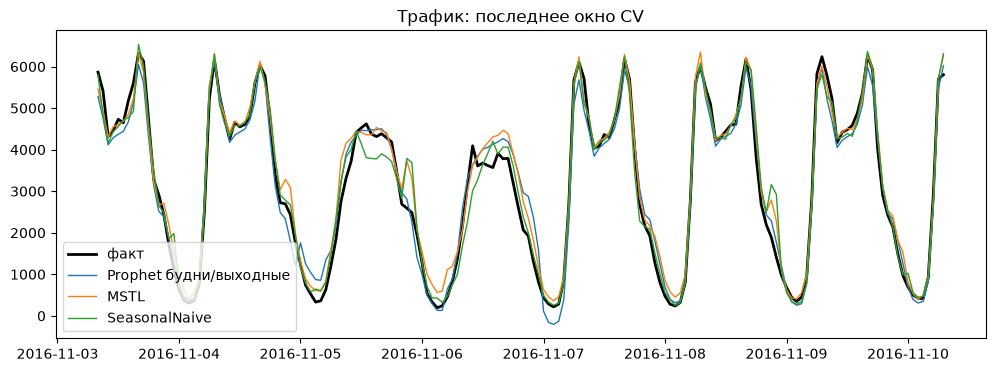

In [17]:
last = hourly[hourly["cutoff"] == hourly["cutoff"].max()]
fig, ax = plt.subplots()
ax.plot(last["ds"], last["y"], color="black", lw=2, label="факт")
for name in ["Prophet будни/выходные", "MSTL", "SeasonalNaive"]:
    ax.plot(last["ds"], last[name], lw=1, label=name)
ax.set_title("Трафик: последнее окно CV")
ax.legend();

- Дефолтный Prophet проигрывает даже «повтору прошлой недели»: один дневной профиль на все дни не описывает разницу будней и выходных.
- С условной сезонностью Prophet почти догоняет SeasonalNaive, но MSTL и AutoTBATS точнее.
- Причина — короткая история (6 недель) и сложный профиль 24 × 7: SeasonalNaive и MSTL просто копируют / сглаживают недавний недельный профиль, а Prophet собирает его из гармоник. И Prophet не использует последние наблюдения, хотя на почасовом ряде соседние часы очень похожи.

Обучение: Prophet и MSTL — секунды, AutoTBATS — около минуты на окно.

## 4. Когда Prophet не брать

### 4.1. Автокорреляция остатков

Prophet — регрессия на функциях времени: остаток $\varepsilon_t$ считается независимым шумом. Если в остатках осталась автокорреляция, модель теряет информацию, которую дали бы последние наблюдения, а интервалы занижены. Остатки на трафике (модель будни/выходные на всей истории):

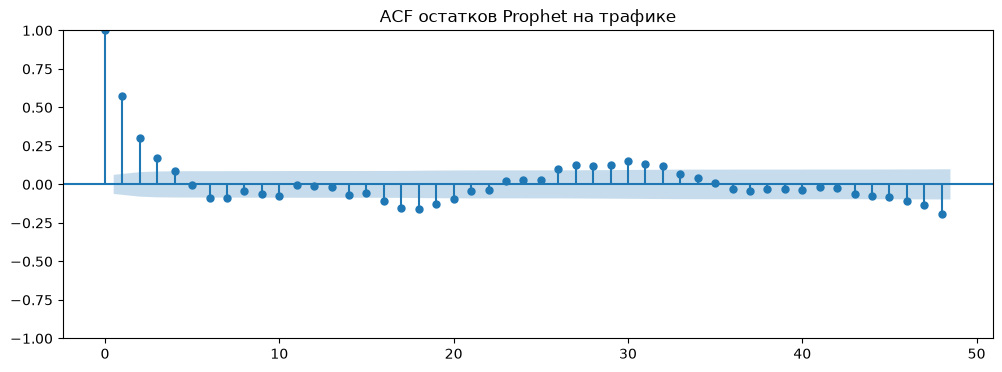

In [18]:
m_traffic = weekday_weekend_prophet().fit(traffic_prophet)
residuals = traffic_prophet["y"] - m_traffic.predict(traffic_prophet.drop(columns="y"))["yhat"]
fig = plot_acf(residuals, lags=48, title="ACF остатков Prophet на трафике")

Корреляция на лаге 1 около 0.6: «если сейчас поток выше прогноза, через час он, скорее всего, тоже выше». Модели вроде ETS / ARIMA / TBATS (с ARMA-ошибками) это используют, Prophet — нет. Признак этого на CV — ошибка Prophet на первых шагах горизонта не меньше, чем на дальних (как на графике раздела 3.1).

Возможное исправление — двухэтапная схема: Prophet для тренда и сезонностей + ARIMA на его остатках. Но тогда теряется главное преимущество — простота.

### 4.2. Нет структуры: случайное блуждание

Prophet всегда найдёт тренд и сезонность, даже если их нет. На случайном блуждании лучший прогноз — последнее значение (`Naive`):

In [19]:
rng = np.random.default_rng(0)
walk = pd.DataFrame({"unique_id": "walk", "ds": pd.date_range("2018-01-01", periods=3 * 365, freq="D")})
walk["y"] = 100 + rng.normal(size=len(walk)).cumsum()

cv_walk = StatsForecast(models=[Naive()], freq="D").cross_validation(df=walk, h=30, n_windows=10, step_size=30)
cv_walk_prophet = cross_validation(Prophet().fit(walk.drop(columns="unique_id")),
                                   cutoffs=pd.to_datetime(cv_walk["cutoff"].unique()), horizon="30 days",
                                   parallel="threads", disable_tqdm=True)
walk_cv = compare({"Prophet": cv_walk_prophet}, cv_walk)
walk_cv[["Prophet", "Naive"]].sub(walk_cv["y"], axis=0).abs().mean().rename("MAE").round(2)

Prophet    5.21
Naive      3.36
Name: MAE, dtype: float64

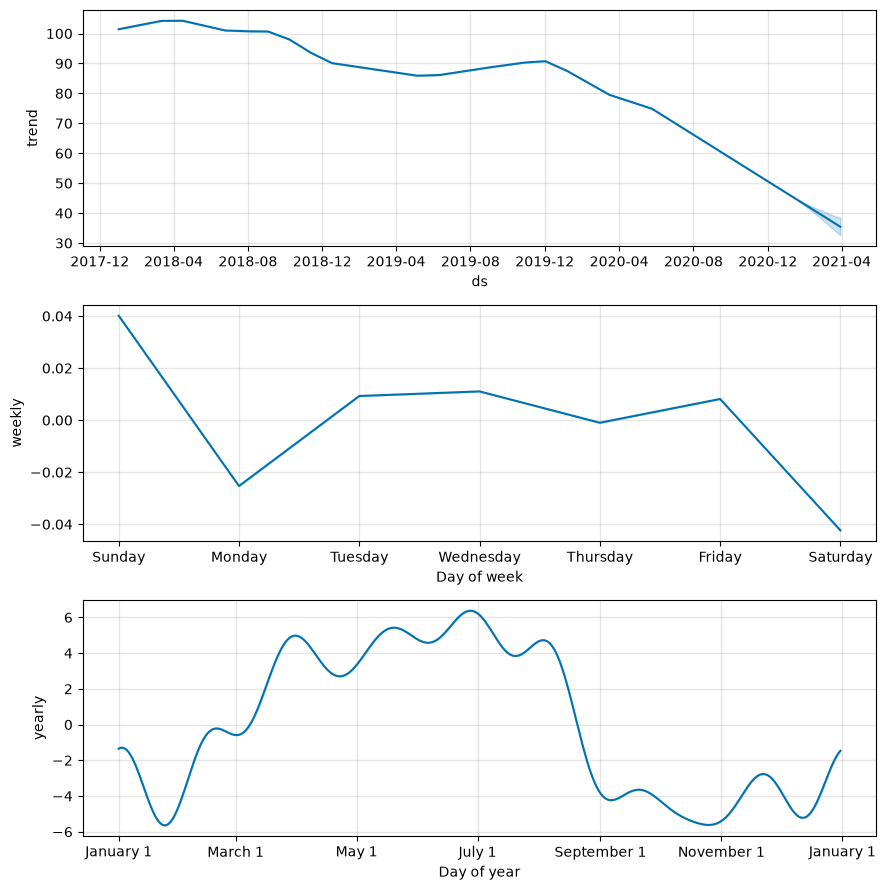

In [20]:
m_walk = Prophet().fit(walk.drop(columns="unique_id"))
fig = m_walk.plot_components(m_walk.predict(m_walk.make_future_dataframe(periods=90)))

Недельная сезонность почти нулевая (±0.04), а вот годовую с размахом ±6 модель «нашла» в чистом шуме: три года блуждания — это всего три «периода», и случайные подъёмы и спады легко принять за сезонность. Тренд продолжает случайный наклон последнего сегмента. Ошибка в полтора раза больше, чем у Naive.

### 4.3. Сводка ограничений

| Ситуация | Что видно на CV | Что делать |
|---|---|---|
| Нет сильной сезонности, мало истории | проигрыш Naive / SeasonalNaive | брать простые модели |
| Важны последние наблюдения (короткий горизонт, высокая частота) | ошибка не растёт с горизонтом, ACF остатков | ETS / ARIMA / TBATS, или ARIMA на остатках |
| Длинный горизонт | ошибка растёт к концу горизонта | `growth='logistic'`/`'flat'`, меньший `changepoint_prior_scale`, сценарии |
| Нужны надёжные интервалы | coverage ниже номинала | калибровка по CV, `mcmc_samples`, конформные интервалы |

Сильная сторона Prophet — много бизнес-рядов с выраженными сезонностями и праздниками, пропуски и нерегулярная сетка, понятные ручки. На таких рядах (Пейтон) он на уровне хороших бейзлайнов. Но проверять это нужно каждый раз — CV против бейзлайнов на тех же отсечках.

## 5. Практика: дообучение и сохранение

### 5.1. Тёплый старт

Prophet нельзя «дообучить» на новых точках — только обучить заново. Но оптимизацию можно начать с параметров старой модели: `warm_start_params` (из `prophet.utilities`) → `fit(..., init=...)`. Настройки модели (сезонности, число изломов) должны совпадать.

In [21]:
m_old = Prophet().fit(df[df["ds"] < df["ds"].max()])  # все данные, кроме последнего дня

start = time.perf_counter()
Prophet().fit(df)
cold = time.perf_counter() - start

start = time.perf_counter()
m_new = Prophet().fit(df, init=warm_start_params(m_old))
warm = time.perf_counter() - start
print(f"с нуля: {cold:.2f} с, тёплый старт: {warm:.2f} с")

с нуля: 0.35 с, тёплый старт: 0.13 с


Выигрыш тем больше, чем меньше изменились оптимальные параметры, — удобно для ежедневного переобучения многих рядов.

### 5.2. Сохранение модели

`pickle` для Prophet не рекомендуется: объект содержит Stan-бэкенд. Встроенная сериализация — JSON (`model_to_json` / `model_from_json`), переносимый и обратно совместимый между версиями.

In [22]:
restored = model_from_json(model_to_json(m_new))
future = m_new.make_future_dataframe(periods=30)
np.allclose(m_new.predict(future)["yhat"], restored.predict(future)["yhat"])

True

В файл — обычной записью строки: `Path("model.json").write_text(model_to_json(m))`.

## Итоги

- **`cross_validation`** — исторические прогнозы на отсечках (`initial` / `period` / `horizon` или `cutoffs`); `performance_metrics` и `plot_cross_validation_metric` показывают ошибку как функцию горизонта.
- **Coverage** проверяет интервалы: у Prophet они, как правило, уже номинала.
- **Тюнинг**: главная ручка — `changepoint_prior_scale`; выбор по CV даёт оптимистичную оценку на тех же отсечках.
- **Бейзлайны на тех же отсечках** — обязательны. На Пейтоне Prophet на уровне MSTL и лучше простых моделей; на коротком почасовом трафике проигрывает MSTL и TBATS.
- **Ограничения**: не использует последние наблюдения (автокорреляция остатков), находит структуру в шуме, линейно экстраполирует тренд, занижает интервалы.